# Exploratory Data Analysis

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
%matplotlib inline
import utils

In [2]:
df=utils.load_data()
print('rows:',len(df),'| classes:',df['label'].nunique())
df.head()

rows: 30000 | classes: 2


,text,label
0,"It all sounds the same, but.... It's all good....",positive
1,"Sedaris can be more than merely ""funny"". I fou...",positive
2,good book. i have not had alot of time to chec...,positive
3,NOT FOR KIDS!. I got this movie for my 6 and 5...,negative
4,Tess by Tess. A sad tale for anyone to read - ...,positive


## Class distribution

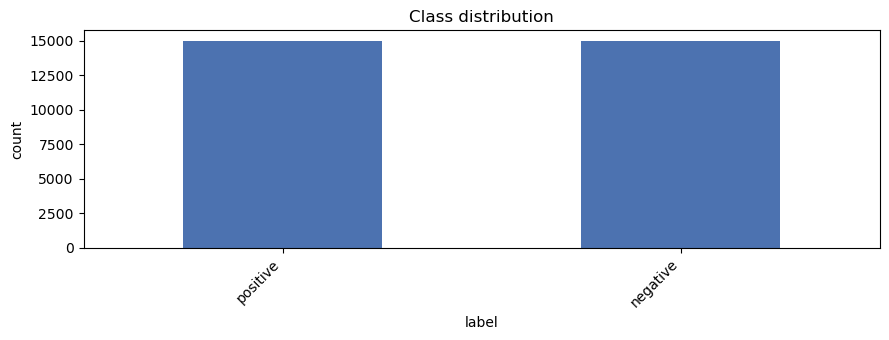

label
positive    15000
negative    15000


In [3]:
fig,ax=plt.subplots(figsize=(9,3.5))
vc=df['label'].value_counts()
vc.plot(kind='bar',ax=ax,color='#4c72b0'); ax.set_title('Class distribution'); ax.set_ylabel('count')
plt.xticks(rotation=45,ha='right'); plt.tight_layout(); plt.show()
print(vc.to_string())

## Length Distriubution

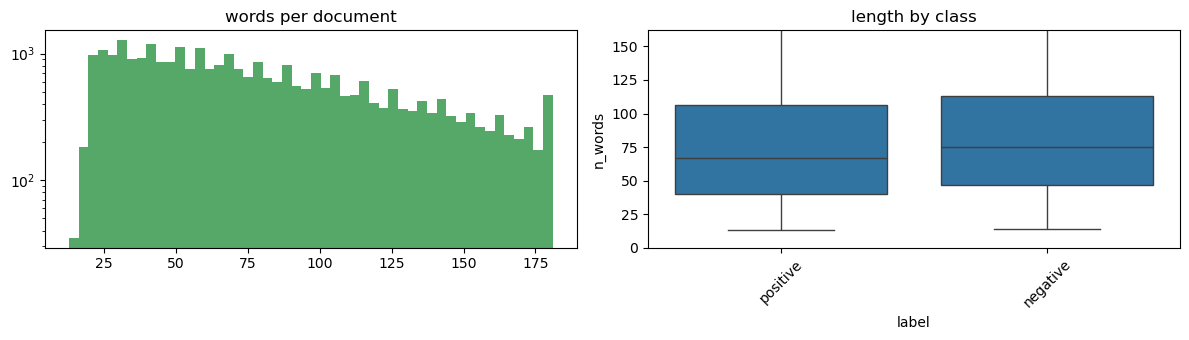

words per doc — median 71, max 212


In [4]:
df['n_words']=df['text'].astype(str).str.split().apply(len)
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
ax[0].hist(df['n_words'].clip(upper=df['n_words'].quantile(0.99)),bins=50,color='#55a868')
ax[0].set_title('words per document')
ax[0].set_yscale('log')
sns.boxplot(x='label',y='n_words',data=df,ax=ax[1])
ax[1].set_ylim(0,df['n_words'].quantile(0.95))
ax[1].set_title('length by class')
ax[1].tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()
print('words per doc — median %d, max %d'%(df['n_words'].median(),df['n_words'].max()))

## Most Frequent Words

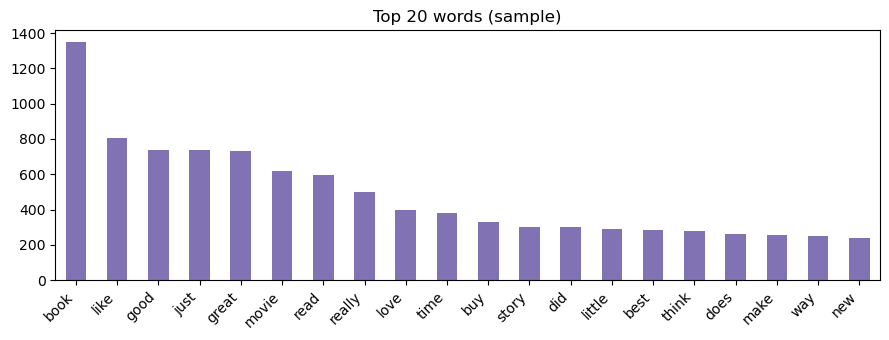

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
words=Counter()
for t in df['text'].astype(str).head(3000):
    words.update(w for w in t.lower().split() if w.isalpha() and w not in ENGLISH_STOP_WORDS and len(w)>2)
top=pd.Series(dict(words.most_common(20)))
fig,ax=plt.subplots(figsize=(9,3.5))
top.plot(kind='bar',ax=ax,color='#8172b3')
ax.set_title('Top 20 words (sample)')
plt.xticks(rotation=45,ha='right')
plt.tight_layout(); plt.show()

## Summary

The raw text and class balance above push to the cleaning and the TF-IDF + classic-ML modelling. Text length and vocabulary vary by class, which is exactly the signal the classifiers will exploit.